In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.stats import norm

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
elif not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "events.csv"

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

events = pd.read_csv(DATA_PATH)

events["timestamp"] = pd.to_datetime(
    events["timestamp"],
    unit="ms",
    utc=True,
    errors="coerce"
)

events = events.dropna(
    subset=["timestamp", "visitorid", "itemid", "event"]
).copy()

events = events.sort_values(
    ["visitorid", "timestamp"]
).reset_index(drop=True)

print("Shape:", events.shape)
print("Period:", events["timestamp"].min(), "—", events["timestamp"].max())
print("Users:", events["visitorid"].nunique())
print("Items:", events["itemid"].nunique())

events.head()

Shape: (2756101, 5)
Period: 2015-05-03 03:00:04.384000+00:00 — 2015-09-18 02:59:47.788000+00:00
Users: 1407580
Items: 235061


,timestamp,visitorid,event,itemid,transactionid
0,2015-09-11 20:49:49.439+00:00,0,view,285930,NaN
1,2015-09-11 20:52:39.591+00:00,0,view,357564,NaN
2,2015-09-11 20:55:17.175+00:00,0,view,67045,NaN
3,2015-08-13 17:46:06.444+00:00,1,view,72028,NaN
4,2015-08-07 17:51:44.567+00:00,2,view,325215,NaN


In [64]:
event_types = ["view", "addtocart", "transaction"]

pair_counts = (
    events[events["event"].isin(event_types)]
    .pivot_table(
        index=["visitorid", "itemid"],
        columns="event",
        values="timestamp",
        aggfunc="size",
        fill_value=0
    )
    .reindex(columns=event_types, fill_value=0)
    .rename(columns={
        "view": "views",
        "addtocart": "addtocarts",
        "transaction": "transactions"
    })
)

first_times = (
    events[events["event"].isin(event_types)]
    .pivot_table(
        index=["visitorid", "itemid"],
        columns="event",
        values="timestamp",
        aggfunc="min"
    )
    .reindex(columns=event_types)
    .rename(columns={
        "view": "first_view",
        "addtocart": "first_addtocart",
        "transaction": "first_transaction"
    })
)

pair_features = pair_counts.join(first_times).reset_index()

for col in ["views", "addtocarts", "transactions"]:
    pair_features[col] = pair_features[col].astype("int32")

pair_features["has_view"] = pair_features["views"] > 0
pair_features["has_addtocart"] = pair_features["addtocarts"] > 0
pair_features["has_transaction"] = pair_features["transactions"] > 0

pair_features["view_before_cart"] = (
    pair_features["first_view"].notna()
    & pair_features["first_addtocart"].notna()
    & (pair_features["first_view"] <= pair_features["first_addtocart"])
)

pair_features["cart_before_transaction"] = (
    pair_features["first_addtocart"].notna()
    & pair_features["first_transaction"].notna()
    & (pair_features["first_addtocart"] <= pair_features["first_transaction"])
)

pair_features["sequential_view_cart"] = pair_features["view_before_cart"]
pair_features["sequential_cart_transaction"] = (
    pair_features["view_before_cart"]
    & pair_features["cart_before_transaction"]
)

pair_features["sequential_full_funnel"] = (
    pair_features["sequential_view_cart"]
    & pair_features["sequential_cart_transaction"]
)

display(pair_features.head())
print("Unique visitor-item pairs:", len(pair_features))


event,visitorid,itemid,views,addtocarts,transactions,first_view,first_addtocart,first_transaction,has_view,has_addtocart,has_transaction,view_before_cart,cart_before_transaction,sequential_view_cart,sequential_cart_transaction,sequential_full_funnel
0,0,67045,1,0,0,2015-09-11 20:55:17.175+00:00,NaT,NaT,True,False,False,False,False,False,False,False
1,0,285930,1,0,0,2015-09-11 20:49:49.439+00:00,NaT,NaT,True,False,False,False,False,False,False,False
2,0,357564,1,0,0,2015-09-11 20:52:39.591+00:00,NaT,NaT,True,False,False,False,False,False,False,False
3,1,72028,1,0,0,2015-08-13 17:46:06.444+00:00,NaT,NaT,True,False,False,False,False,False,False,False
4,2,216305,2,0,0,2015-08-07 18:01:08.920+00:00,NaT,NaT,True,False,False,False,False,False,False,False


Unique visitor-item pairs: 2145179


In [65]:
users_with_view = funnel_users[0]
users_view_and_cart = funnel_users[1]
users_all_three = funnel_users[2]

users_with_cart = int(user_event_times["addtocart"].notna().sum())
users_with_transaction = int(
    user_event_times["transaction"].notna().sum()
)

baseline_metrics = pd.DataFrame({
    "Metric": [
        "Total users",
        "Users with view",
        "Users with add to cart",
        "Users with transaction",
        "Sequential View to Cart conversion",
        "Sequential Cart to Transaction conversion",
        "Sequential View to Transaction conversion"
    ],
    "Value": [
        len(user_event_times),
        users_with_view,
        users_with_cart,
        users_with_transaction,
        users_view_and_cart / users_with_view,
        users_all_three / users_view_and_cart,
        users_all_three / users_with_view
    ]
})

display(baseline_metrics)

,Metric,Value
0,Total users,"1,407,580.0000"
1,Users with view,"1,404,179.0000"
2,Users with add to cart,"37,722.0000"
3,Users with transaction,"11,719.0000"
4,Sequential View to Cart conversion,0.0230
5,Sequential Cart to Transaction conversion,0.3000
6,Sequential View to Transaction conversion,0.0069


In [66]:
baseline_metrics.to_csv(
    TABLES_DIR / "10_baseline_metrics.csv",
    index=False
)

In [67]:
user_event_times = (
    events[events["event"].isin(["view", "addtocart", "transaction"])]
    .pivot_table(
        index="visitorid",
        columns="event",
        values="timestamp",
        aggfunc="min"
    )
    .reindex(columns=["view", "addtocart", "transaction"])
)

user_event_times["view"] = user_event_times["view"]

user_event_times["view_to_cart"] = (
    user_event_times["view"].notna()
    & user_event_times["addtocart"].notna()
    & (user_event_times["view"] <= user_event_times["addtocart"])
)

user_event_times["view_cart_transaction"] = (
    user_event_times["view_to_cart"]
    & user_event_times["transaction"].notna()
    & (user_event_times["addtocart"] <= user_event_times["transaction"])
)

funnel_users = [
    int(user_event_times["view"].notna().sum()),
    int(user_event_times["view_to_cart"].sum()),
    int(user_event_times["view_cart_transaction"].sum())
]


funnel = pd.DataFrame({
    "stage": ["View", "Add to cart", "Transaction"],
    "users": funnel_users
})

funnel["conversion_from_view"] = (
    funnel["users"] / funnel.loc[0, "users"]
)

funnel["conversion_from_previous"] = (
    funnel["users"] / funnel["users"].shift(1)
)

funnel.loc[0, "conversion_from_previous"] = 1.0

display(funnel)

,stage,users,conversion_from_view,conversion_from_previous
0,View,1404179,1.0000,1.0000
1,Add to cart,32272,0.0230,0.0230
2,Transaction,9682,0.0069,0.3000


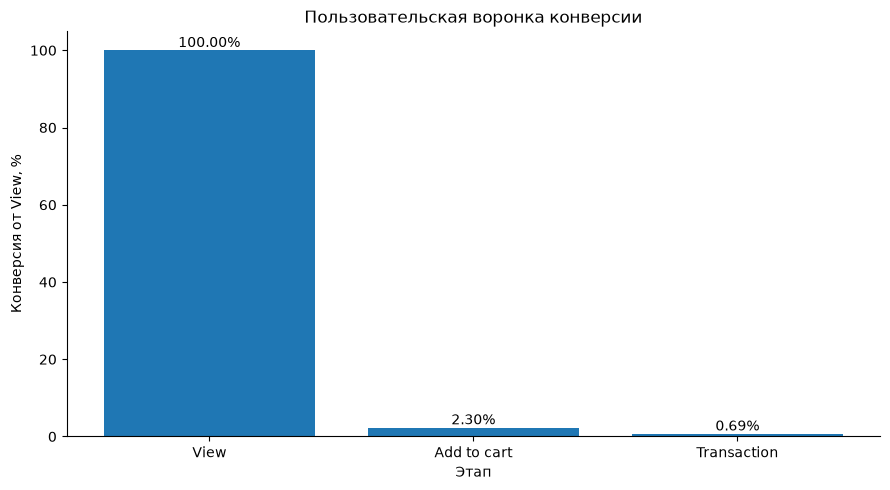

In [68]:
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    funnel["stage"],
    funnel["conversion_from_view"] * 100
)

ax.set_title("Пользовательская воронка конверсии")
ax.set_ylabel("Конверсия от View, %")
ax.set_xlabel("Этап")

for bar, value in zip(
    bars,
    funnel["conversion_from_view"] * 100
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "10_user_funnel.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [69]:
hypotheses = pd.DataFrame([
    {
        "id": "H1",
        "problem": "Низкая конверсия View → Add to cart",
        "hypothesis": (
            "Если улучшить карточку товара и сделать информацию "
            "о товаре более понятной, конверсия в корзину вырастет."
        ),
        "change": "Изменение карточки товара",
        "primary_metric": "Add to cart conversion",
        "guardrail_metric": "Purchase conversion",
        "priority": "High"
    },
    {
        "id": "H2",
        "problem": "Пользователи возвращаются к товарам",
        "hypothesis": (
            "Если добавить возможность сохранять товары, "
            "пользователи будут чаще возвращаться к ним."
        ),
        "change": "Добавление избранного",
        "primary_metric": "Repeat visits",
        "guardrail_metric": "Purchase conversion",
        "priority": "Medium"
    },
    {
        "id": "H3",
        "problem": "Потери после добавления в корзину",
        "hypothesis": (
            "Если упростить процесс оформления заказа, "
            "больше пользователей завершат покупку."
        ),
        "change": "Упрощение checkout",
        "primary_metric": "Cart to purchase conversion",
        "guardrail_metric": "View to purchase conversion",
        "priority": "High"
    },
    {
        "id": "H4",
        "problem": "Различия в конверсии товаров",
        "hypothesis": (
            "Если улучшить представление товаров с большим числом "
            "просмотров и низкой конверсией, их конверсия увеличится."
        ),
        "change": "Оптимизация представления товара",
        "primary_metric": "View to purchase conversion",
        "guardrail_metric": "Purchase conversion",
        "priority": "Medium"
    }
])

hypotheses

,id,problem,hypothesis,change,primary_metric,guardrail_metric,priority
0,H1,Низкая конверсия View → Add to cart,Если улучшить карточку товара и сделать информ...,Изменение карточки товара,Add to cart conversion,Purchase conversion,High
1,H2,Пользователи возвращаются к товарам,"Если добавить возможность сохранять товары, по...",Добавление избранного,Repeat visits,Purchase conversion,Medium
2,H3,Потери после добавления в корзину,"Если упростить процесс оформления заказа, боль...",Упрощение checkout,Cart to purchase conversion,View to purchase conversion,High
3,H4,Различия в конверсии товаров,Если улучшить представление товаров с большим ...,Оптимизация представления товара,View to purchase conversion,Purchase conversion,Medium


In [70]:
hypotheses.to_csv(
    TABLES_DIR / "10_product_hypotheses.csv",
    index=False
)

In [71]:
ice_scores = pd.DataFrame([
    {
        "id": "H1",
        "impact": 9,
        "confidence": 7,
        "ease": 7
    },
    {
        "id": "H2",
        "impact": 5,
        "confidence": 5,
        "ease": 8
    },
    {
        "id": "H3",
        "impact": 9,
        "confidence": 7,
        "ease": 5
    },
    {
        "id": "H4",
        "impact": 6,
        "confidence": 5,
        "ease": 6
    }
])

ice_scores["ICE_score"] = (
    ice_scores["impact"]
    * ice_scores["confidence"]
    * ice_scores["ease"]
)

ice_scores = ice_scores.sort_values(
    "ICE_score",
    ascending=False
)

ice_scores

,id,impact,confidence,ease,ICE_score
0,H1,9,7,7,441
2,H3,9,7,5,315
1,H2,5,5,8,200
3,H4,6,5,6,180


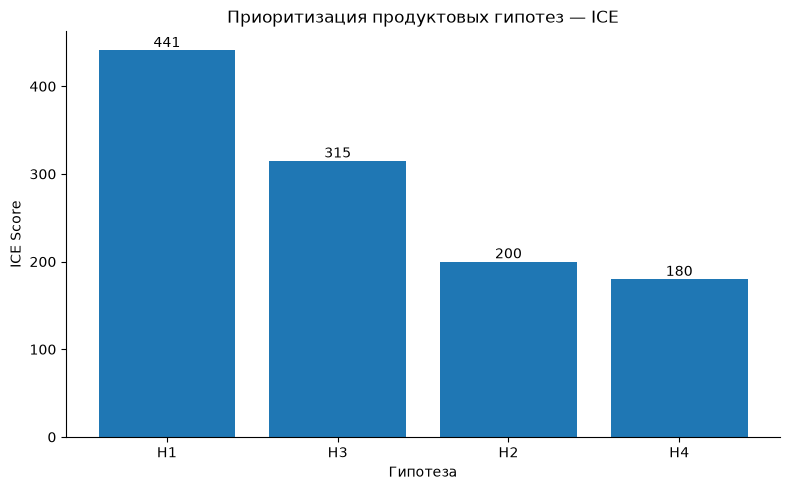

In [72]:
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ice_scores["id"],
    ice_scores["ICE_score"]
)

ax.set_title("Приоритизация продуктовых гипотез — ICE")
ax.set_xlabel("Гипотеза")
ax.set_ylabel("ICE Score")

for bar, value in zip(bars, ice_scores["ICE_score"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(value),
        ha="center",
        va="bottom"
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "10_ice_prioritization.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [73]:
baseline_conversion = (
    funnel.loc[1, "users"] / funnel.loc[0, "users"]
)

relative_mde = 0.10

alpha = 0.05
power = 0.80

p1 = baseline_conversion
p2 = p1 * (1 + relative_mde)

z_alpha = norm.ppf(1 - alpha / 2)
z_beta = norm.ppf(power)

p_bar = (p1 + p2) / 2

sample_size = (
    (
        z_alpha * np.sqrt(2 * p_bar * (1 - p_bar))
        + z_beta * np.sqrt(
            p1 * (1 - p1) + p2 * (1 - p2)
        )
    ) ** 2
    / (p2 - p1) ** 2
)

sample_size = int(np.ceil(sample_size))

sample_size_results = pd.DataFrame({
    "metric": [
        "Baseline conversion",
        "Target conversion",
        "Relative MDE",
        "Absolute MDE",
        "Significance level",
        "Statistical power",
        "Sample size per group",
        "Total sample size"
    ],
    "value": [
        p1,
        p2,
        relative_mde,
        p2 - p1,
        alpha,
        power,
        sample_size,
        sample_size * 2
    ]
})

display(sample_size_results)

,metric,value
0,Baseline conversion,0.0230
1,Target conversion,0.0253
2,Relative MDE,0.1000
3,Absolute MDE,0.0023
4,Significance level,0.0500
5,Statistical power,0.8000
6,Sample size per group,"69,986.0000"
7,Total sample size,"139,972.0000"


In [74]:
sample_size_results.to_csv(
    TABLES_DIR / "10_sample_size_calculation.csv",
    index=False
)

In [75]:
final_summary = pd.DataFrame({
    "metric": [
        "Total users",
        "Users with views",
        "Baseline view-to-cart conversion",
        "Baseline cart-to-purchase conversion",
        "Baseline view-to-purchase conversion",
        "Number of hypotheses",
        "Sample size per group",
        "Total required sample size"
    ],
    "value": [
        events["visitorid"].nunique(),
        funnel.loc[0, "users"],
        funnel.loc[1, "conversion_from_view"],
        funnel.loc[2, "conversion_from_previous"],
        funnel.loc[2, "conversion_from_view"],
        len(hypotheses),
        sample_size,
        sample_size * 2
    ]
})

display(final_summary)

,metric,value
0,Total users,"1,407,580.0000"
1,Users with views,"1,404,179.0000"
2,Baseline view-to-cart conversion,0.0230
3,Baseline cart-to-purchase conversion,0.3000
4,Baseline view-to-purchase conversion,0.0069
5,Number of hypotheses,4.0000
6,Sample size per group,"69,986.0000"
7,Total required sample size,"139,972.0000"


In [76]:
final_summary.to_csv(
    TABLES_DIR / "10_final_summary.csv",
    index=False
)

print("Notebook 10 analysis completed.")

print("\nSaved tables:")
for file in sorted(TABLES_DIR.glob("10_*.csv")):
    print(file.name)

print("\nSaved figures:")
for file in sorted(FIGURES_DIR.glob("10_*.png")):
    print(file.name)

Notebook 10 analysis completed.

Saved tables:
10_baseline_metrics.csv
10_final_summary.csv
10_product_hypotheses.csv
10_sample_size_calculation.csv

Saved figures:
10_ice_prioritization.png
10_user_funnel.png
